# 04. Đánh giá 6 fold và fusion

Một hàng/người; không chia ngẫu nhiên theo tác vụ. Cùng fold cho tất cả nhánh. Imputer/scaler chỉ fit trên train. F1 mặc định trong báo cáo là macro. Các bảng xếp hạng là CV nội bộ, chưa phải đánh giá ngoài độc lập.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
print('Project:', ROOT)


Project: E:\DiaGraMo-project


In [2]:
summary=pd.read_csv(ROOT/'results/cv/summary.csv')
print('CV configurations:',len(summary))
summary.head(20)

CV configurations: 168


,representation,classifier,n_features,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy,mean_accuracy,...,mean_f1_weighted,mean_f1_binary,mean_auc,mean_balanced_accuracy,std_accuracy,std_f1_macro,std_f1_weighted,std_f1_binary,std_auc,std_balanced_accuracy
0,kinematic,LightGBM,1036,0.848837,0.847163,0.848899,0.863158,0.906902,0.847461,0.848837,...,0.848836,0.862942,0.904027,0.847276,0.032056,0.032387,0.032058,0.029750,0.031284,0.032343
1,kinematic,XGBoost,1036,0.841085,0.838106,0.840489,0.860068,0.911766,0.836212,0.841085,...,0.840100,0.858979,0.911315,0.835612,0.022865,0.021739,0.022254,0.027174,0.026521,0.020059
2,kinematic,AdaBoost,1036,0.810078,0.807647,0.809994,0.829268,0.891760,0.807388,0.810078,...,0.809853,0.828138,0.889397,0.807661,0.047471,0.046999,0.047065,0.048034,0.039351,0.044737
3,kinematic,RandomForest,1036,0.806202,0.797323,0.801927,0.839744,0.868015,0.792825,0.806202,...,0.800057,0.841491,0.869346,0.793489,0.063547,0.070972,0.068378,0.045566,0.039439,0.070703
4,Kinematic+GAF,XGBoost,11788,0.798450,0.793980,0.797273,0.824324,0.874673,0.791791,0.798450,...,0.796739,0.824179,0.875922,0.791679,0.060046,0.062550,0.061318,0.051509,0.026860,0.062080
5,kinematic,SVM,1036,0.798450,0.789915,0.794511,0.832258,0.861295,0.785832,0.798450,...,0.793553,0.832326,0.863018,0.786257,0.037977,0.041324,0.039390,0.029869,0.060899,0.042263
6,Kinematic+CWT,LightGBM,26124,0.794574,0.790722,0.793803,0.819113,0.864032,0.789146,0.794574,...,0.792451,0.819863,0.860269,0.789930,0.053875,0.057793,0.056692,0.041254,0.023471,0.058489
7,Kinematic+CWT,XGBoost,26124,0.782946,0.777600,0.781342,0.812081,0.867437,0.775251,0.782946,...,0.780465,0.811760,0.875950,0.775186,0.080112,0.081836,0.081067,0.072556,0.021816,0.082376
8,kinematic,LogisticRegression,1036,0.782946,0.781051,0.783262,0.801418,0.867254,0.782061,0.782946,...,0.782787,0.798326,0.863441,0.782374,0.087840,0.086884,0.086915,0.088788,0.070857,0.083959
9,Kinematic+GAF,AdaBoost,11788,0.779070,0.775833,0.778757,0.802768,0.861538,0.775160,0.779070,...,0.776485,0.802363,0.863844,0.774053,0.073173,0.078640,0.076093,0.060942,0.056915,0.077508


In [3]:
folds=pd.read_csv(ROOT/'results/cv/fold_assignments.csv')
assert folds.participant_id.is_unique
pd.crosstab(folds.fold,folds.label)

label,0,1
fold,,
0,20,23
1,19,24
2,19,24
3,19,24
4,19,24
5,19,24


In [4]:
pd.read_csv(ROOT/'results/comparison_paper.csv')

,representation,classifier,paper_acc,local_acc,delta_acc_pp,paper_f1_unspecified,local_f1_macro,paper_auc,local_mean_auc,local_pooled_auc
0,moment,LogisticRegression,65.1,63.178295,-1.921705,65.1,62.122761,70.1,69.961543,70.270599
1,moment,RandomForest,65.1,67.829457,2.729457,63.3,64.478986,71.4,72.636823,72.654302
2,moment,SVM,70.2,67.829457,-2.370543,69.9,64.792442,74.9,75.069444,74.618425
3,kinematic,XGBoost,82.2,84.108527,1.908527,81.9,83.765343,89.9,91.131452,91.176649
4,kinematic,LightGBM,82.9,84.883721,1.983721,82.8,84.704657,90.5,90.402682,90.690179
5,kinematic,AdaBoost,83.7,81.007752,-2.692248,83.6,80.763936,90.1,88.939741,89.176041
6,gaf_efficientnet_b4,XGBoost,65.9,66.279070,0.379070,65.3,64.252238,71.8,74.344012,72.867133
7,gaf_vgg16,RandomForest,68.6,68.217054,-0.382946,67.0,65.967015,72.2,71.406369,71.380359
8,gaf_vit_b_16,LightGBM,73.3,63.178295,-10.121705,73.0,61.653288,78.5,66.302441,65.953177
9,cwt_vgg16,SVM,66.3,57.751938,-8.548062,66.0,41.423615,70.8,58.402142,52.353299


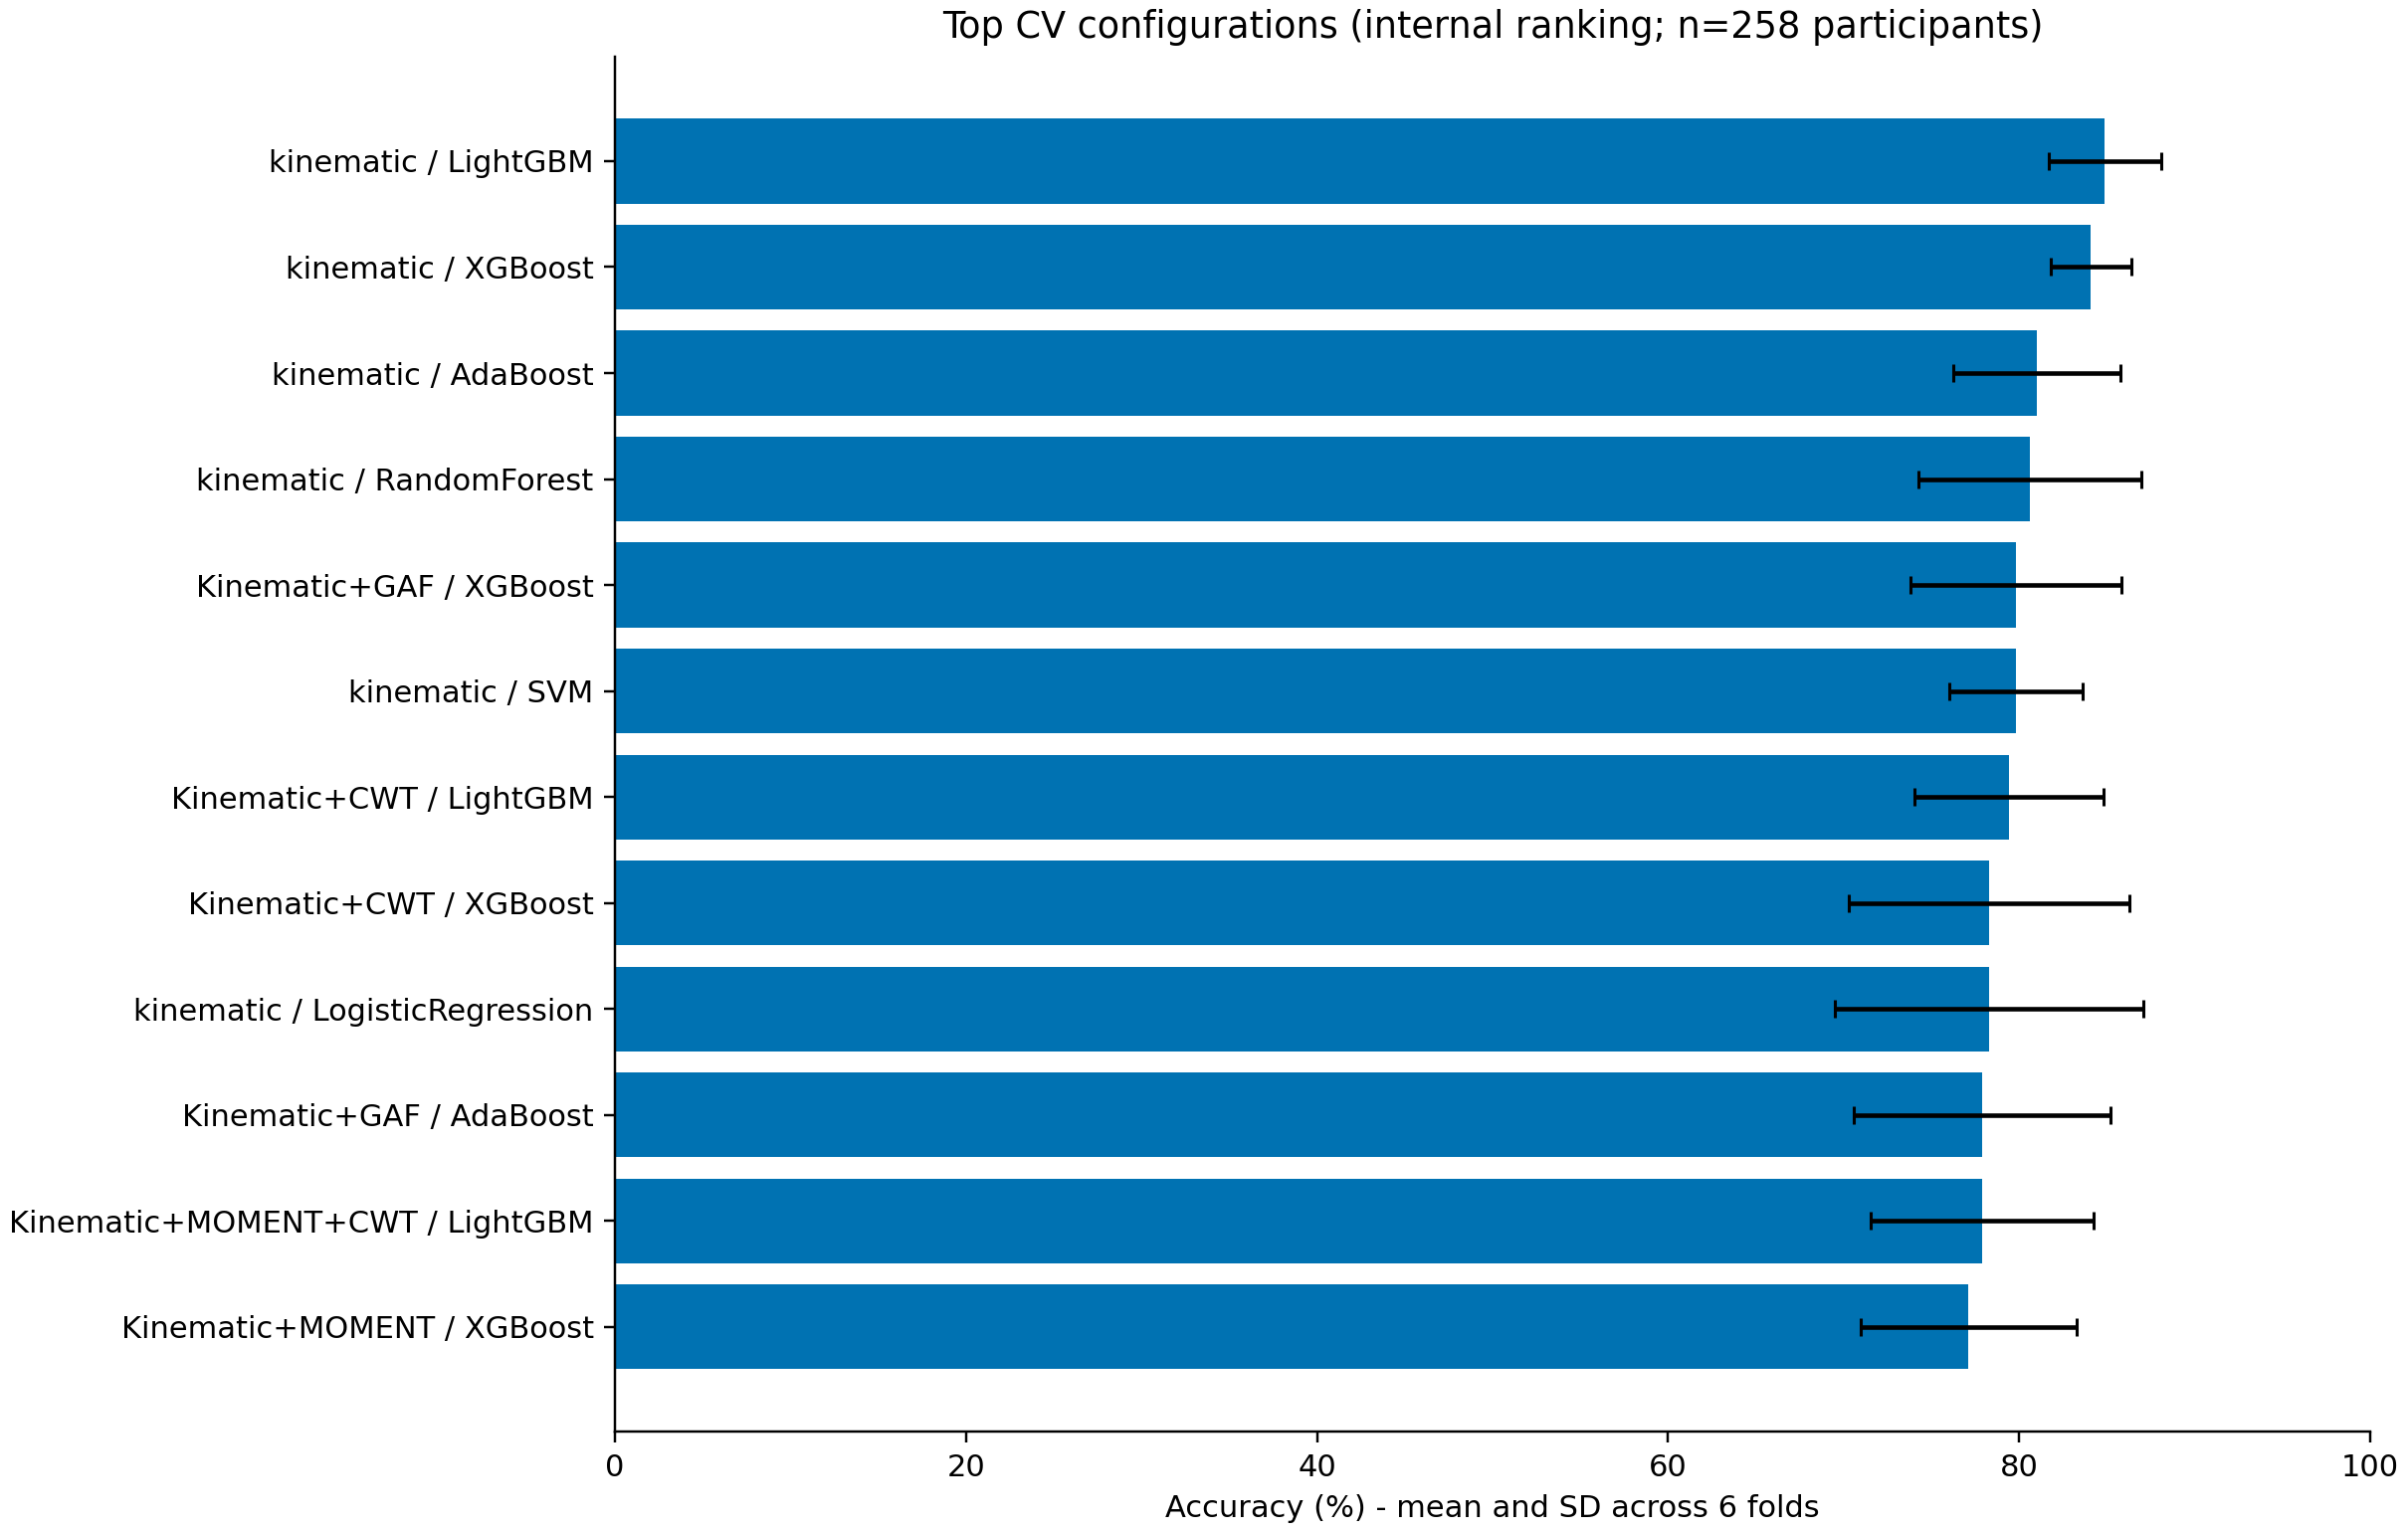

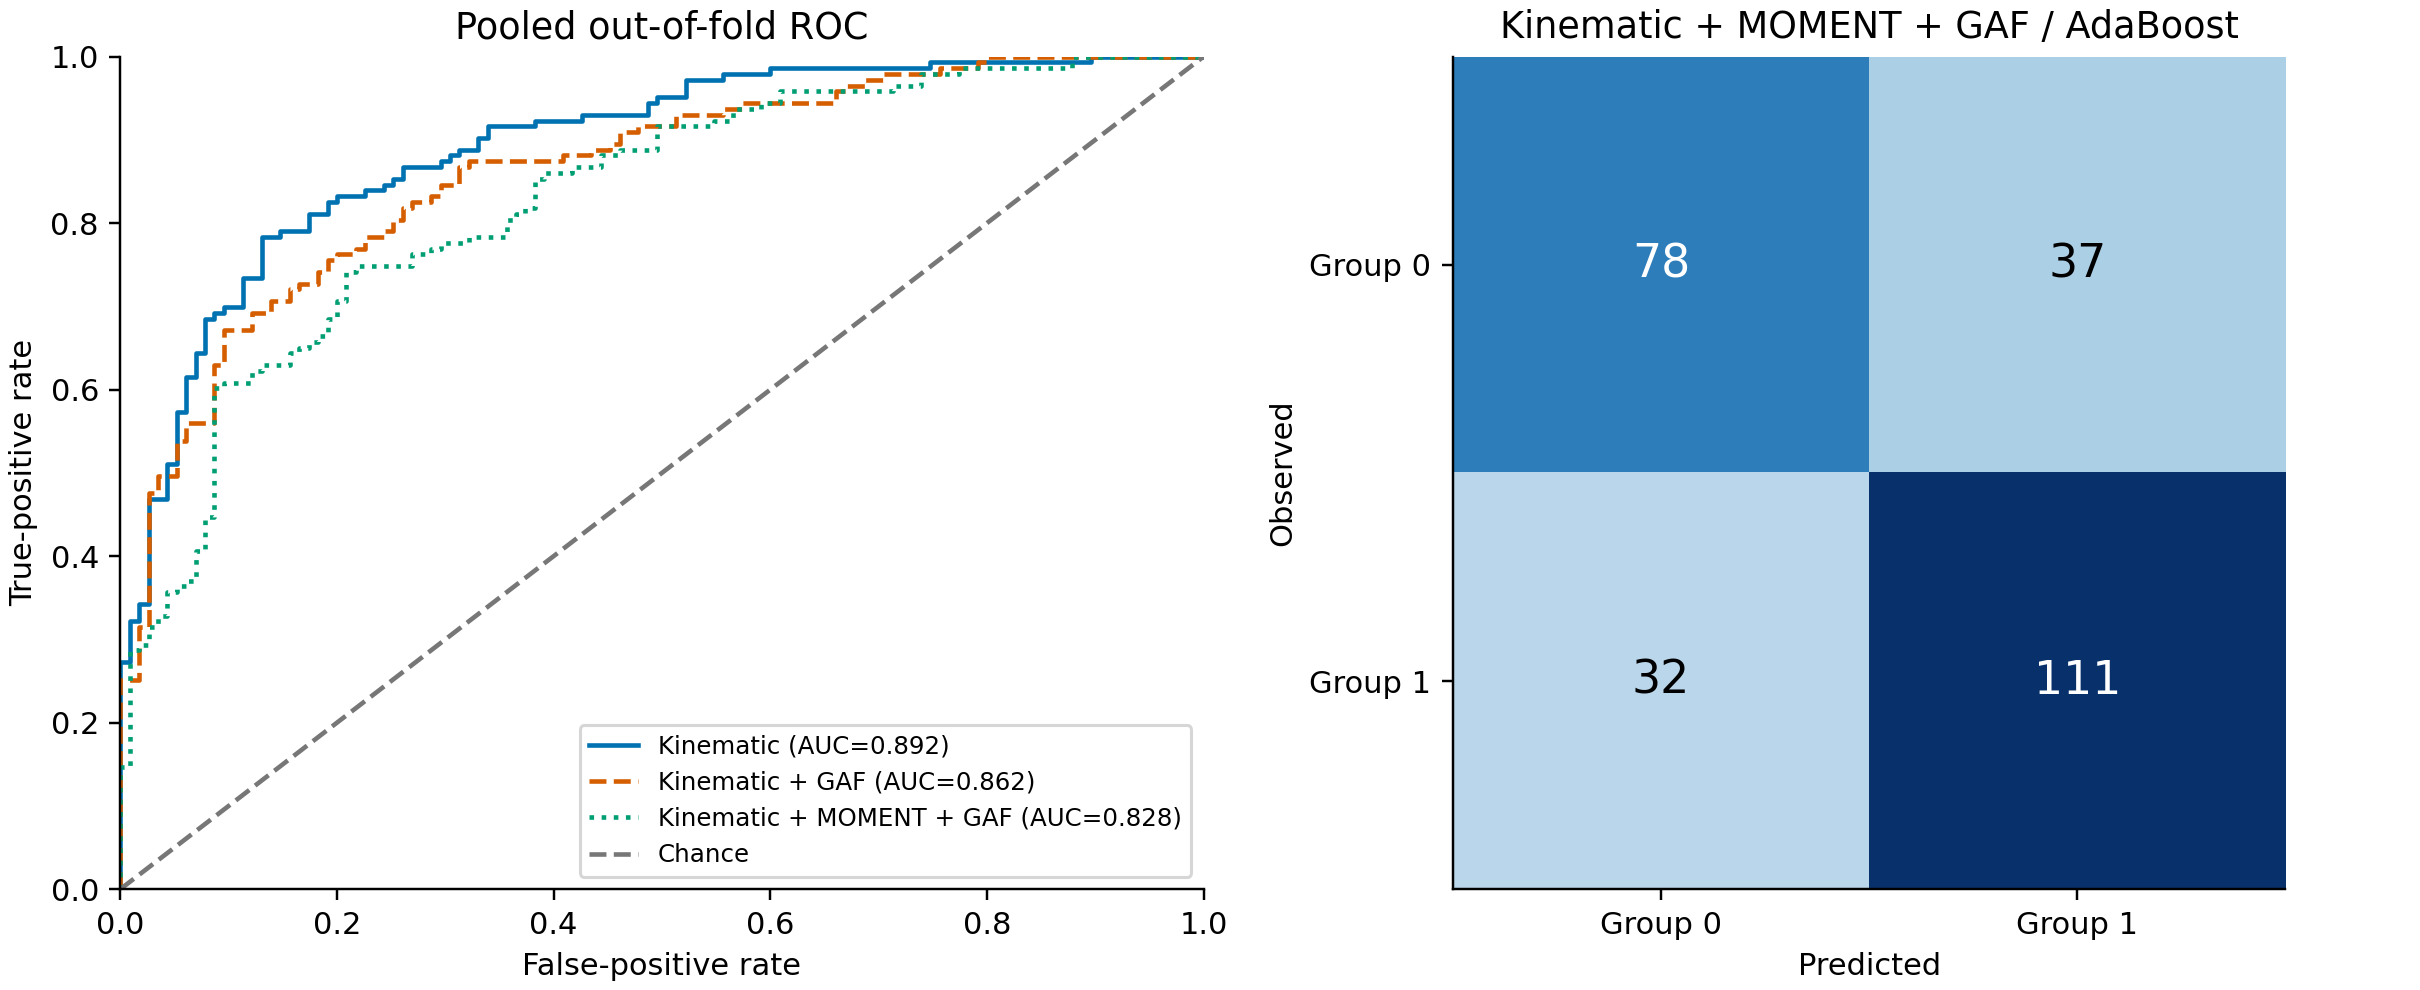

In [5]:
from IPython.display import Image,display
display(Image(filename=str(ROOT/'results/figures/cv_top12.png')))
display(Image(filename=str(ROOT/'results/figures/roc_confusion.png')))

In [6]:
p=ROOT/'results/sensitivity/summary.csv'
pd.read_csv(p) if p.exists() else 'Phân tích nhạy cảm chưa chạy'

,scenario,classifier,n,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy
0,group_all,AdaBoost,258,0.810078,0.807647,0.809994,0.829268,0.891760,0.807388
1,group_all,LightGBM,258,0.848837,0.847163,0.848899,0.863158,0.906902,0.847461
2,diagnosis_same_cohort,AdaBoost,258,0.810078,0.809249,0.810321,0.821818,0.880508,0.810351
3,diagnosis_same_cohort,LightGBM,258,0.810078,0.807647,0.809491,0.829268,0.892433,0.806356
4,group_without_omit_flags,AdaBoost,255,0.819608,0.817244,0.819608,0.838028,0.896360,0.817244
5,group_without_omit_flags,LightGBM,255,0.807843,0.806881,0.808431,0.820513,0.892870,0.810295


In [7]:
json.loads((ROOT/'results/validation.json').read_text())

{'complete': True,
 'published_configurations_complete': True,
 'published_configurations_finished': 15,
 'published_configurations_expected': 15,
 'expected_results': 168,
 'actual_results': 168,
 'oof_files_validated': 168,
 'expected_representations': ['GAF+CWT',
  'Kinematic+CWT',
  'Kinematic+GAF',
  'Kinematic+GAF+CWT',
  'Kinematic+MOMENT',
  'Kinematic+MOMENT+CWT',
  'Kinematic+MOMENT+GAF',
  'Kinematic+MOMENT+GAF+CWT',
  'MOMENT+CWT',
  'MOMENT+GAF',
  'MOMENT+GAF+CWT',
  'cwt_efficientnet_b4',
  'cwt_resnet50',
  'cwt_vgg16',
  'cwt_vit_b_16',
  'gaf_efficientnet_b4',
  'gaf_resnet50',
  'gaf_vgg16',
  'gaf_vit_b_16',
  'kinematic',
  'moment']}